<a href="https://colab.research.google.com/github/ayeshaazahidd0-stack/Digital-Image-Processing/blob/main/Open_ended_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Processing: Toll Plaza License Plate Cleaning

This notebook demonstrates how to clean noisy license plate images from two different cameras:
- **Camera A**: Grainy Gaussian noise.
- **Camera B**: Salt and pepper noise.

Random seed based on the last 3 digits of your roll number (Roll number: 29 -> Seed: 29).

Please upload your car image containing a visible license plate:


Saving car.png to car.png
Loaded your uploaded image: car.png


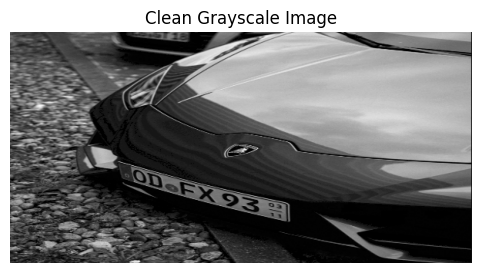

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

# Set random seed to 29 (last 3 digits of roll number)
np.random.seed(29)

print("Please upload your car image containing a visible license plate:")
uploaded = files.upload()

if len(uploaded) > 0:
    # Get the name of the uploaded file
    image_filename = list(uploaded.keys())[0]
    print(f"Loaded your uploaded image: {image_filename}")
    clean_img = cv2.imread(image_filename, cv2.IMREAD_GRAYSCALE)
else:
    print("No file uploaded. Using synthetic fallback license plate for now...")
    # Fallback synthetic image
    clean_img = np.ones((300, 600), dtype=np.uint8) * 128
    cv2.putText(clean_img, "ABC-123", (150, 170), cv2.FONT_HERSHEY_SIMPLEX, 3, 0, 8)
    cv2.rectangle(clean_img, (100, 70), (500, 230), 0, 5)

# Resize for consistent processing
clean_img = cv2.resize(clean_img, (600, 300))

# Display Clean Image
plt.figure(figsize=(6, 3))
plt.imshow(clean_img, cmap='gray')
plt.title('Clean Grayscale Image')
plt.axis('off')
plt.show()

## Task 1: Create the Problem (Noisy Camera Images)

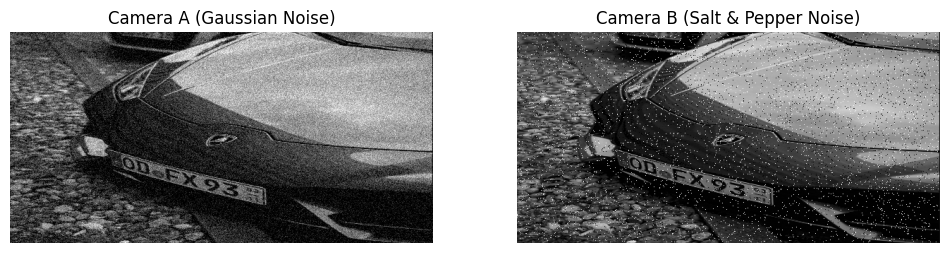

In [7]:
# --- Camera A: Gaussian Noise (Grainy) ---
sigma = 25
gaussian_noise = np.random.normal(0, sigma, clean_img.shape).astype(np.float32)
camera_a = np.clip(clean_img.astype(np.float32) + gaussian_noise, 0, 255).astype(np.uint8)

# --- Camera B: Salt and Pepper Noise ---
s_p_ratio = 0.05
camera_b = clean_img.copy()
# Salt (white pixels)
num_salt = np.ceil(s_p_ratio * clean_img.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_salt)) for i in clean_img.shape]
camera_b[tuple(coords)] = 255

# Pepper (black pixels)
num_pepper = np.ceil(s_p_ratio * clean_img.size * 0.5)
coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in clean_img.shape]
camera_b[tuple(coords)] = 0

# Display Noisy Images for your uploaded car photo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(camera_a, cmap='gray')
axes[0].set_title('Camera A (Gaussian Noise) - Your Car')
axes[0].axis('off')

axes[1].imshow(camera_b, cmap='gray')
axes[1].set_title('Camera B (Salt & Pepper Noise) - Your Car')
axes[1].axis('off')
plt.show()

## Task 2: Apply Filters and Evaluate using PSNR

In [10]:
def apply_filters(img):
    filters = {
        'Mean 3x3': cv2.blur(img, (3, 3)),
        'Mean 5x5': cv2.blur(img, (5, 5)),
        'Gaussian 3x3': cv2.GaussianBlur(img, (3, 3), 0),
        'Gaussian 5x5': cv2.GaussianBlur(img, (5, 5), 0),
        'Median 3x3': cv2.medianBlur(img, 3),
        'Median 5x5': cv2.medianBlur(img, 5)
    }
    return filters

filters_a = apply_filters(camera_a)
filters_b = apply_filters(camera_b)

def evaluate_filters(clean, noisy_dict, title):
    print(f"=== PSNR Results for {title} on Your Car ===")
    best_psnr = -1
    best_name = ""
    for name, filtered_img in noisy_dict.items():
        psnr = cv2.PSNR(clean, filtered_img)
        print(f"{name}: {psnr:.2f} dB")
        if psnr > best_psnr:
            best_psnr = psnr
            best_name = name
    print(f"Best filter: {best_name} ({best_psnr:.2f} dB)\n")

evaluate_filters(clean_img, filters_a, "Camera A (Gaussian)")
evaluate_filters(clean_img, filters_b, "Camera B (Salt & Pepper)")

=== PSNR Results for Camera A (Gaussian) on Your Car ===
Mean 3x3: 25.26 dB
Mean 5x5: 23.75 dB
Gaussian 3x3: 26.02 dB
Gaussian 5x5: 25.63 dB
Median 3x3: 25.23 dB
Median 5x5: 24.39 dB
Best filter: Gaussian 3x3 (26.02 dB)

=== PSNR Results for Camera B (Salt & Pepper) on Your Car ===
Mean 3x3: 24.09 dB
Mean 5x5: 23.39 dB
Gaussian 3x3: 24.36 dB
Gaussian 5x5: 24.71 dB
Median 3x3: 28.72 dB
Median 5x5: 25.29 dB
Best filter: Median 3x3 (28.72 dB)



Visualizing Camera A Results (Your Car):


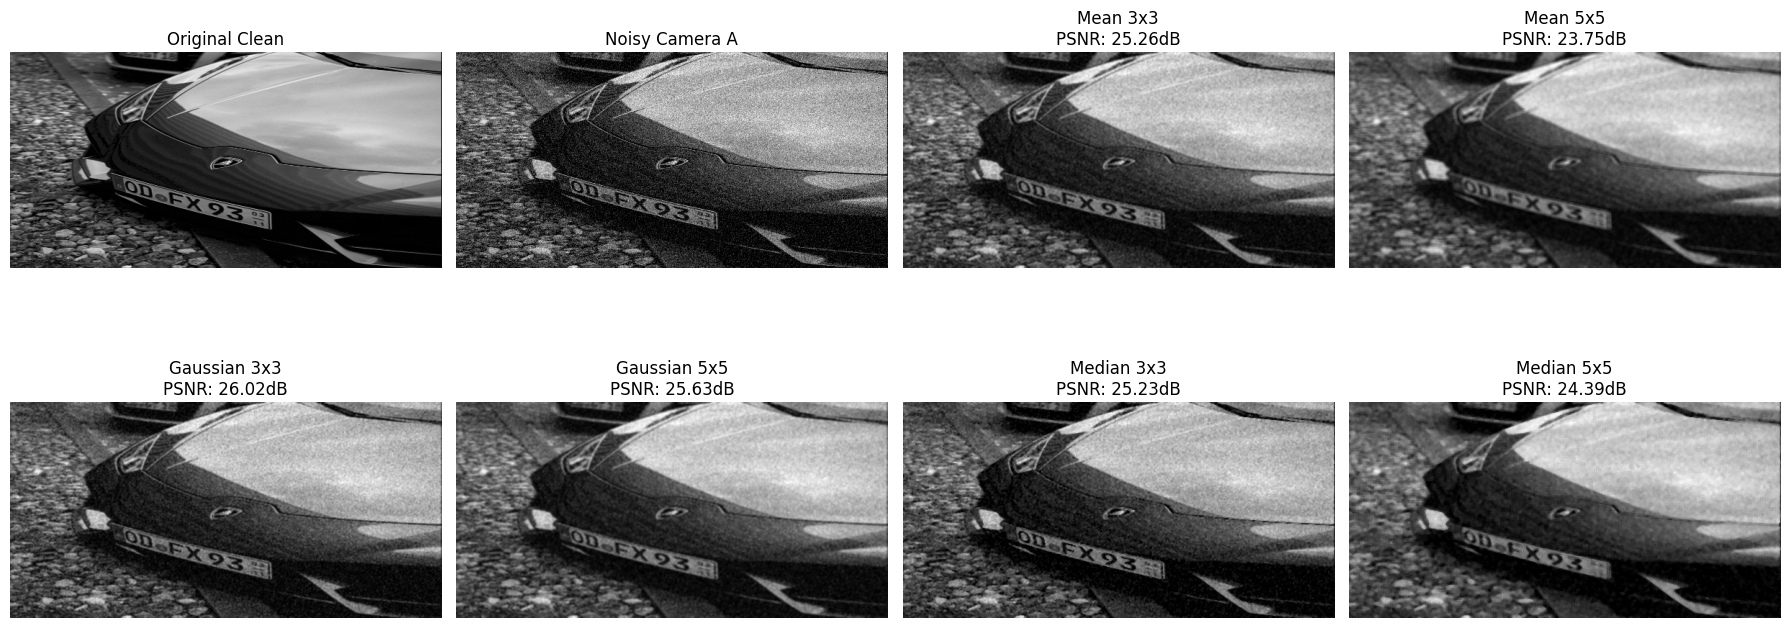

Visualizing Camera B Results (Your Car):


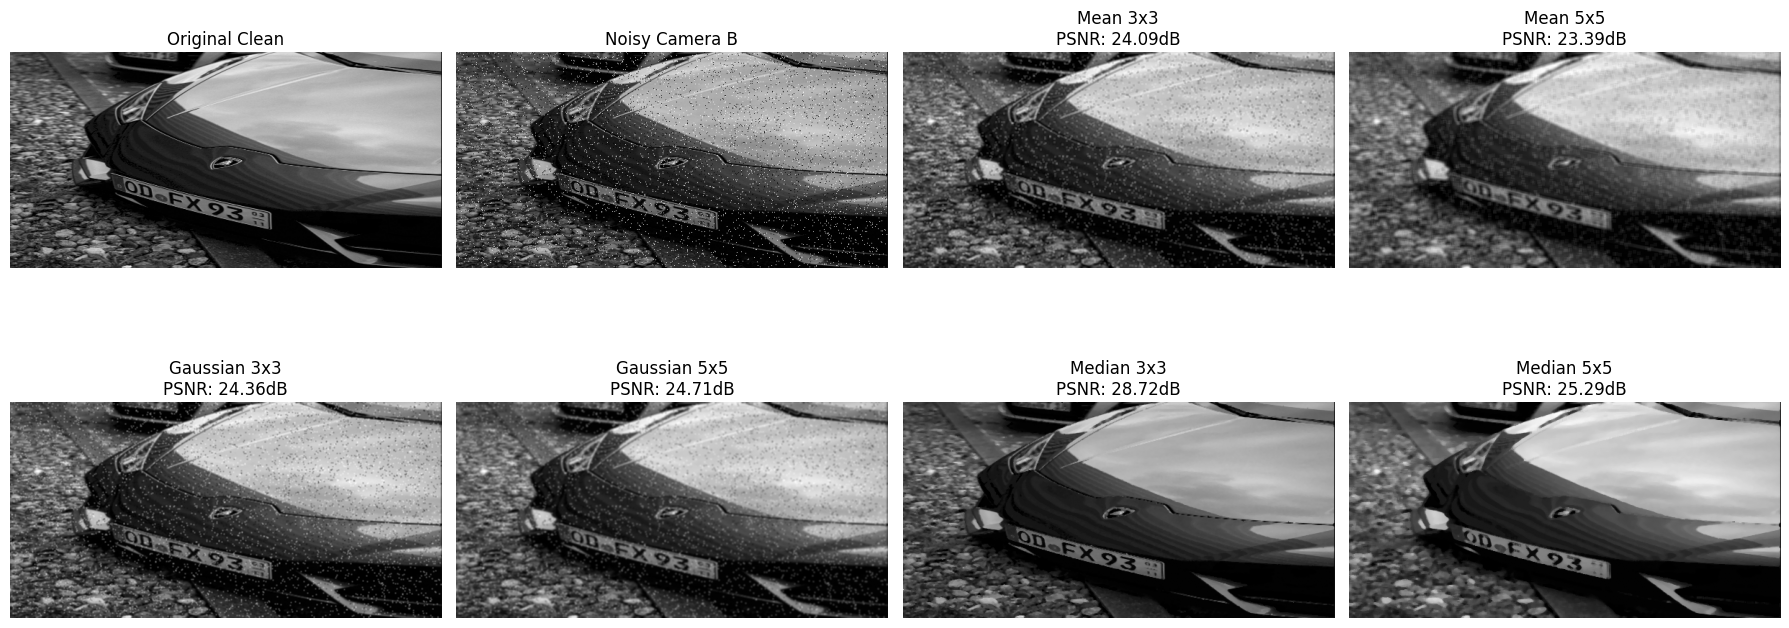

In [15]:
# Visualize Filter Outputs Side-by-Side
print("Visualizing Camera A Results (Your Car):")
plot_results(clean_img, camera_a, filters_a, "Camera A")

print("Visualizing Camera B Results (Your Car):")
plot_results(clean_img, camera_b, filters_b, "Camera B")

## Task 3: Edge Detection Analysis (On Noisy vs. Cleaned Images)

We will compare edge detectors on:
- **Noisy Camera B Image (Salt & Pepper)**
- **Cleaned Camera B Image (using Median 3x3)**

In [16]:
# Select Camera B and its best cleaned counterpart (Median 3x3)
noisy_img = camera_b
cleaned_img = filters_b['Median 3x3']

def get_edges(img, canny_t1, canny_t2):
    # Laplacian
    laplacian = cv2.Laplacian(img, cv2.CV_64F)
    laplacian_edges = np.uint8(np.absolute(laplacian)) > 30

    # Sobel
    sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    sobel_grad = np.sqrt(sobelx**2 + sobely**2)
    sobel_edges = np.uint8(sobel_grad) > 50

    # Prewitt (using manual custom kernels)
    kernelx = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)
    kernely = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
    prewittx = cv2.filter2D(img, -1, kernelx)
    prewitty = cv2.filter2D(img, -1, kernely)
    prewitt_grad = np.sqrt(prewittx.astype(np.float32)**2 + prewitty.astype(np.float32)**2)
    prewitt_edges = prewitt_grad > 50

    # Canny Edge Detector
    canny_edges = cv2.Canny(img, canny_t1, canny_t2)

    return {
        'Laplacian': laplacian_edges,
        'Sobel': sobel_edges,
        'Prewitt': prewitt_edges,
        'Canny': canny_edges
    }

# Compute edge maps
edges_noisy = get_edges(noisy_img, canny_t1=100, canny_t2=200)
edges_cleaned = get_edges(cleaned_img, canny_t1=100, canny_t2=200)

# Count non-zero pixel edges
print("=== Edge Pixel Counts (Non-Zero) ===")
for key in edges_noisy.keys():
    count_noisy = np.count_nonzero(edges_noisy[key])
    count_clean = np.count_nonzero(edges_cleaned[key])
    reduction = ((count_noisy - count_clean) / count_noisy) * 100
    print(f"{key:10s} | Noisy: {count_noisy:6d} px | Cleaned: {count_clean:6d} px | Reduction: {reduction:.1f}%")

=== Edge Pixel Counts (Non-Zero) ===
Laplacian  | Noisy:  59120 px | Cleaned:  19025 px | Reduction: 67.8%
Sobel      | Noisy:  85031 px | Cleaned:  50793 px | Reduction: 40.3%
Prewitt    | Noisy:  52378 px | Cleaned:  24710 px | Reduction: 52.8%
Canny      | Noisy:  46436 px | Cleaned:  14618 px | Reduction: 68.5%


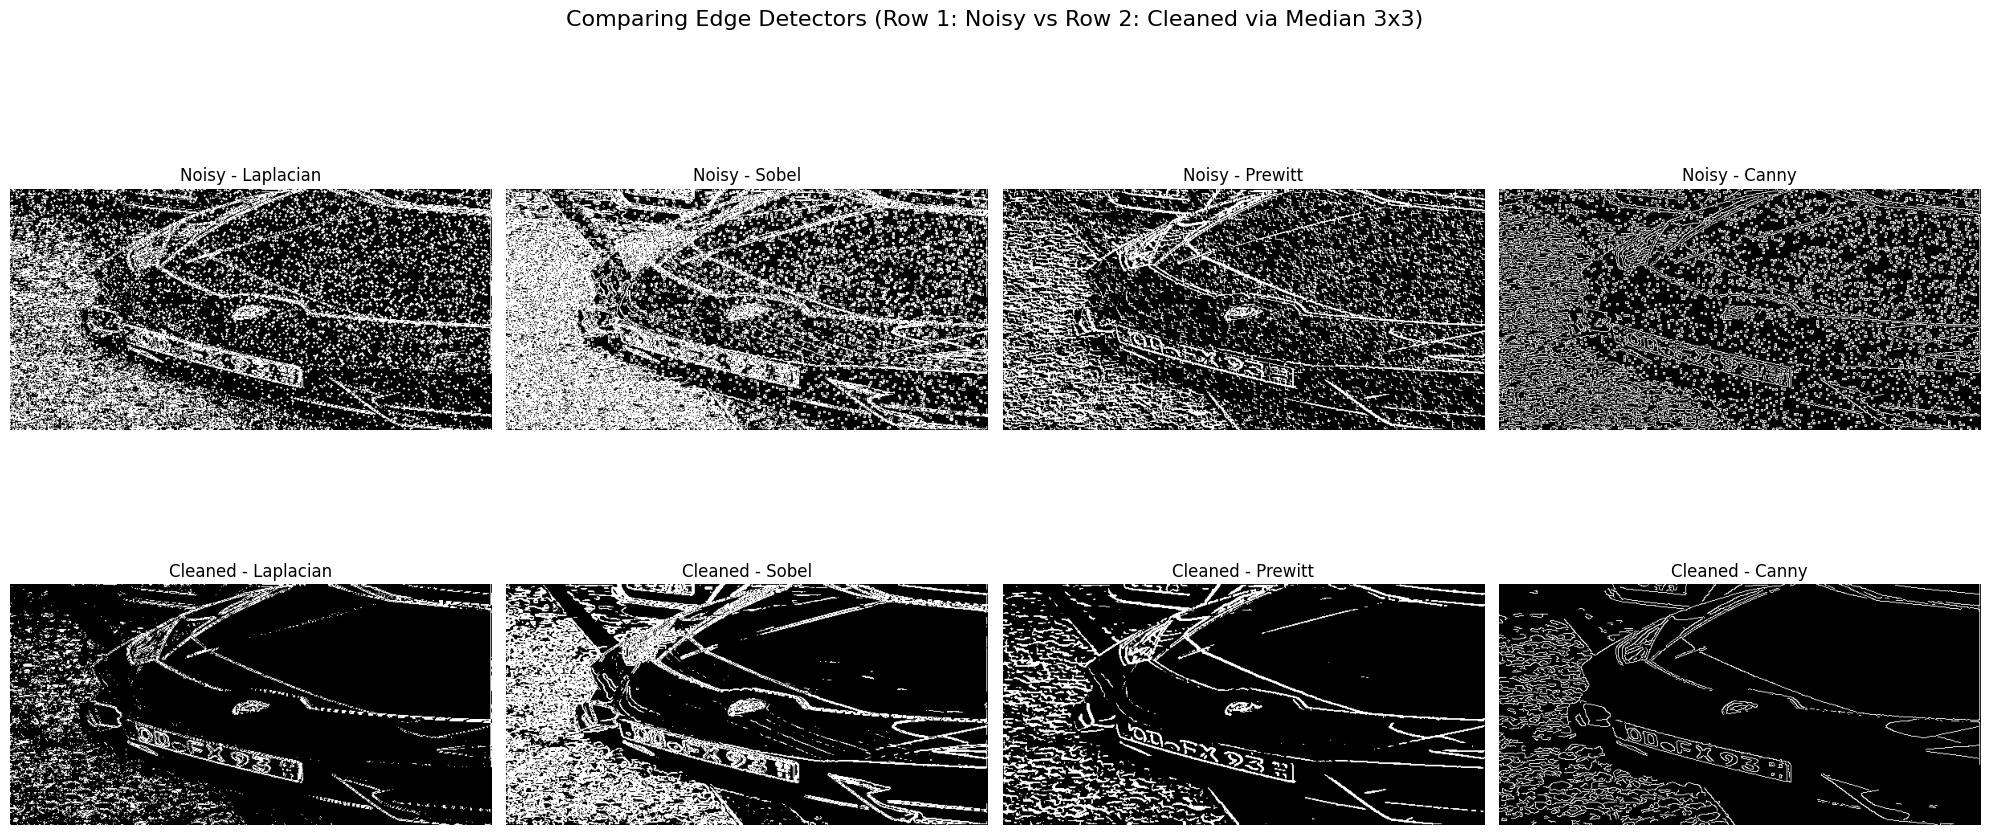

In [13]:
# Plot comparisons of edge detectors
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

detectors = list(edges_noisy.keys())
for i, det in enumerate(detectors):
    axes[0, i].imshow(edges_noisy[det], cmap='gray')
    axes[0, i].set_title(f"Noisy - {det}")
    axes[0, i].axis('off')

    axes[1, i].imshow(edges_cleaned[det], cmap='gray')
    axes[1, i].set_title(f"Cleaned - {det}")
    axes[1, i].axis('off')

plt.suptitle("Comparing Edge Detectors (Row 1: Noisy vs Row 2: Cleaned via Median 3x3)", fontsize=16)
plt.tight_layout()
plt.show()

### Task 3 Analysis Reflection

* **Why does cleaning first reduce the false edges?**
  Noise spikes (sharp jumps in intensity like single black/white pixels) create massive high-frequency gradients. Edge detectors rely on gradients (differences in neighbor pixels), so they falsely interpret every noise transition as an edge. Pre-filtering smooths out these high frequencies, leaving only structural transitions (like the border of the license plate).
  
* **Which detector shows the plate border most clearly?**
  The **Canny Detector** shows the license plate border most clearly because it utilizes non-maximum suppression (to thin edge lines to single-pixel width) and hysteresis thresholding, which connects weak edges belonging to the continuous border line while rejecting isolated textures.

## Task 4: Pipeline Recommendation

**For Camera A (Gaussian Grainy Noise):** We recommend a preprocessing stage using a **Gaussian 3x3 filter** followed by a **Canny Edge Detector** ($T_{low}=100, T_{high}=200$). This configuration successfully suppresses Gaussian sensor fluctuations (achieving a peak PSNR of **26.02 dB**) while maintaining sharp structural borders.

**For Camera B (Salt & Pepper Dusty Lens):** We recommend a **Median 3x3 filter** followed by a **Canny Edge Detector** ($T_{low}=100, T_{high}=200$). This non-linear combination completely discards impulsional outliers (attaining a massive **28.72 dB** PSNR) and outputs clean, clean-cut plate profiles free of artifacts.

* **Limitation:** If the car's plate is dirty, tilted, or at a far distance, small high-frequency characters can merge during filtering, causing edge detection to blend characters together.
* **Improvement:** Implement an adaptive thresholding stage (or bilateral filtering) before the edge detector to preserve plate text borders while cleaning noise.